In [1]:

# Diğer gerekli paketleri yükleyin
libraries <- c(
    "plotly",
    "corrplot",
    "pastecs",
    "dplyr",
    "factoextra",
    "tidyverse",
    "ggplot2",
    "reshape2",
    "caret",
    "cluster",
    "ggpubr",
    "caret"
)

load_libraries <- function(libraries) {
  for (lib in libraries) {
    if (!require(lib, character.only = TRUE)) {
      install.packages(lib, dependencies = TRUE)
      suppressPackageStartupMessages(library(lib, character.only = TRUE))
    } else {
      suppressPackageStartupMessages(library(lib, character.only = TRUE))
    }
  }
}

# Paketleri yükleyin ve yüklemeyi kontrol edin
load_libraries(libraries)


Zorunlu paket yükleniyor: plotly

Zorunlu paket yükleniyor: ggplot2


Attaching package: ‘plotly’


The following object is masked from ‘package:ggplot2’:

    last_plot


The following object is masked from ‘package:stats’:

    filter


The following object is masked from ‘package:graphics’:

    layout


Zorunlu paket yükleniyor: corrplot

corrplot 0.92 loaded

Zorunlu paket yükleniyor: pastecs

Zorunlu paket yükleniyor: dplyr


Attaching package: ‘dplyr’


The following objects are masked from ‘package:pastecs’:

    first, last


The following objects are masked from ‘package:stats’:

    filter, lag


The following objects are masked from ‘package:base’:

    intersect, setdiff, setequal, union


Zorunlu paket yükleniyor: factoextra

Welcome! Want to learn more? See two factoextra-related books at https://goo.gl/ve3WBa

Zorunlu paket yükleniyor: tidyverse

── Attaching core tidyverse packages ──────────────────────── tidyverse 2.0.0 ──
✔ forcats   1.0.0     ✔ stringr   1.5.1
✔ lu

In [2]:
seeds <- read.csv("Seed_Data.csv", header = FALSE)
head(seeds)
seeds <- seeds[-1, ]
head(seeds)
col_names <- c("Area", "Perimeter", "Compactness", "Length_of_Kernel", "Width_of_Kernel", "Asymmetry_Coefficient", "Length_of_Kernel_Groove", "Varieties_of_Wheat")


,V1,V2,V3,V4,V5,V6,V7,V8
,<chr>,<chr>,<chr>,<chr>,<chr>,<chr>,<chr>,<chr>
1,A,P,C,LK,WK,A_Coef,LKG,target
2,15.26,14.84,0.871,5.763,3.312,2.221,5.22,0
3,14.88,14.57,0.8811,5.554,3.333,1.018,4.956,0
4,14.29,14.09,0.905,5.291,3.337,2.699,4.825,0
5,13.84,13.94,0.8955,5.324,3.379,2.259,4.805,0
6,16.14,14.99,0.9034,5.658,3.562,1.355,5.175,0


,V1,V2,V3,V4,V5,V6,V7,V8
,<chr>,<chr>,<chr>,<chr>,<chr>,<chr>,<chr>,<chr>
2,15.26,14.84,0.871,5.763,3.312,2.221,5.22,0
3,14.88,14.57,0.8811,5.554,3.333,1.018,4.956,0
4,14.29,14.09,0.905,5.291,3.337,2.699,4.825,0
5,13.84,13.94,0.8955,5.324,3.379,2.259,4.805,0
6,16.14,14.99,0.9034,5.658,3.562,1.355,5.175,0
7,14.38,14.21,0.8951,5.386,3.312,2.462,4.956,0


In [3]:
colnames(seeds) <- col_names
dim(seeds)
head(seeds)
seeds <- data.frame(lapply(seeds, as.numeric))

[1] 210   8

,Area,Perimeter,Compactness,Length_of_Kernel,Width_of_Kernel,Asymmetry_Coefficient,Length_of_Kernel_Groove,Varieties_of_Wheat
,<chr>,<chr>,<chr>,<chr>,<chr>,<chr>,<chr>,<chr>
2,15.26,14.84,0.871,5.763,3.312,2.221,5.22,0
3,14.88,14.57,0.8811,5.554,3.333,1.018,4.956,0
4,14.29,14.09,0.905,5.291,3.337,2.699,4.825,0
5,13.84,13.94,0.8955,5.324,3.379,2.259,4.805,0
6,16.14,14.99,0.9034,5.658,3.562,1.355,5.175,0
7,14.38,14.21,0.8951,5.386,3.312,2.462,4.956,0


In [4]:
seeds$Varieties_of_Wheat <- factor(seeds$Varieties_of_Wheat)


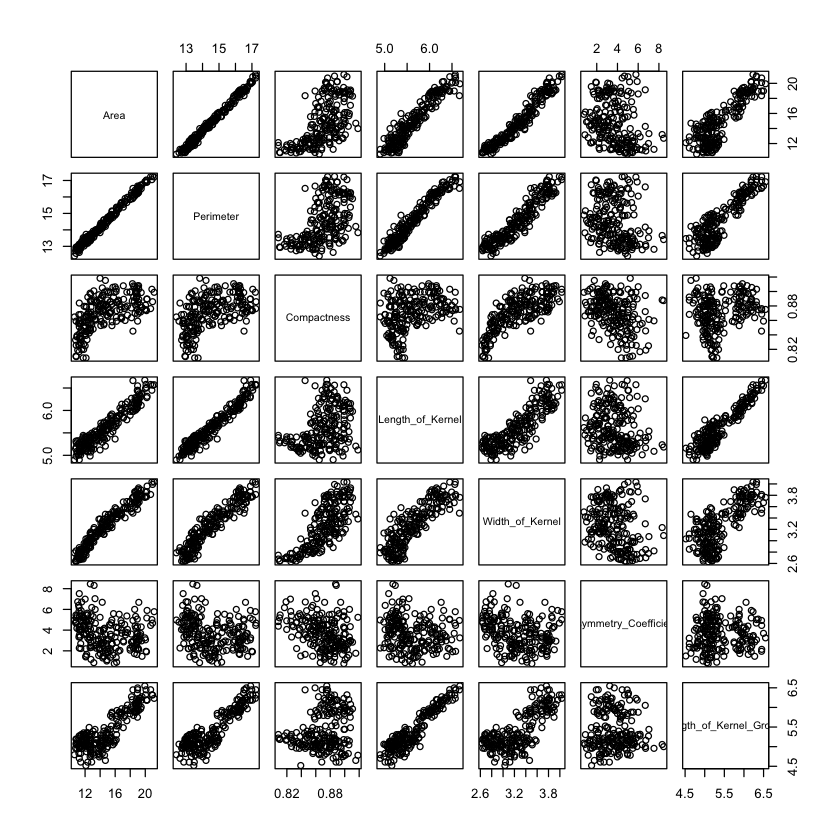

In [5]:

plot(seeds[,1:7])
scale_data <- scale(seeds[1:7], center = TRUE, scale = TRUE)


No id variables; using all as measure variables

No id variables; using all as measure variables



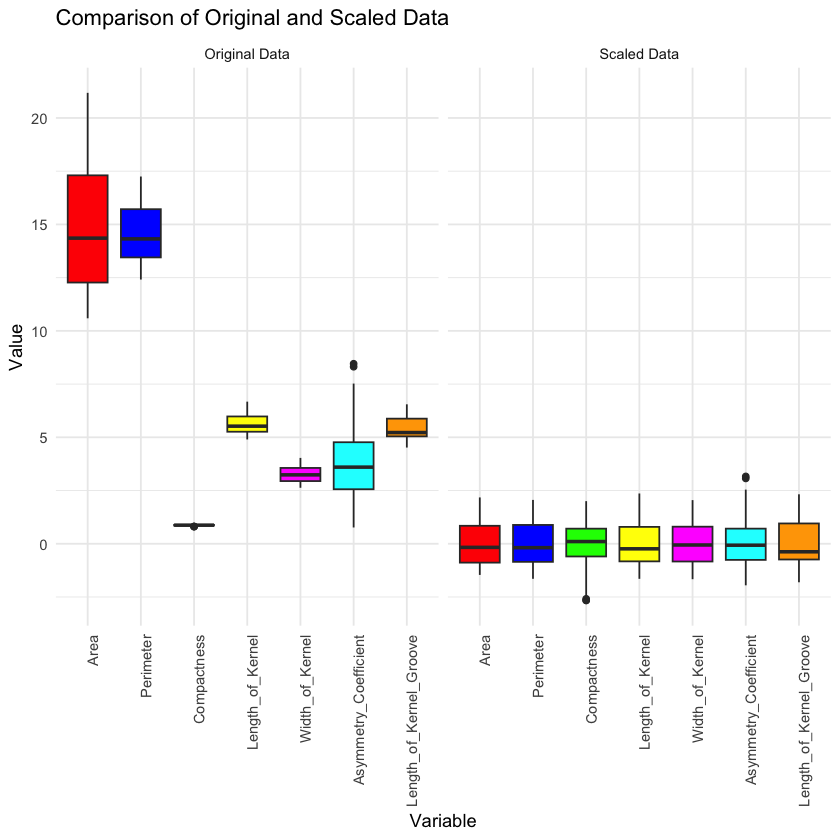

In [6]:

# seeds veri setindeki sadece 7 sütunu seçme
seeds <- seeds[, 1:7]

# Veri setlerini uzun formata çevirme
seeds_long <- melt(seeds, variable.name = "variable", value.name = "value")
scale_data_long <- melt(as.data.frame(scale_data), variable.name = "variable", value.name = "value")

# Kaynak sütununu ekleme
seeds_long$source <- "Original Data"
scale_data_long$source <- "Scaled Data"

# Veri çerçevelerini birleştirme
combined_data <- rbind(seeds_long, scale_data_long)

# Faktör seviyelerini aynı sırada ayarlama
combined_data$variable <- factor(combined_data$variable, levels = unique(combined_data$variable))

# Farklı renkler belirleme
variable_colors <- c(
  "Area" = "#FF0000",
  "Perimeter" = "#0000FF",
  "Compactness" = "#00FF00",
  "Length_of_Kernel" = "#FFFF00",
  "Width_of_Kernel" = "#FF00FF",
  "Asymmetry_Coefficient" = "#00FFFF",
  "Length_of_Kernel_Groove" = "#FFA500"
)

# Boxplot'u çizme
ggplot(combined_data, aes(y = variable, x = value, fill = variable)) +
  geom_boxplot() +
  facet_wrap(~ source, ncol = 2) +
  scale_fill_manual(values = variable_colors) +
  labs(title = "Comparison of Original and Scaled Data",
       x = "Value", y = "Variable") +
  theme_minimal() +
  theme(legend.position = "none",
        axis.text.x = element_text(angle = 90, hjust = 1)) +
  coord_flip()




Importance of components:
                          PC1    PC2     PC3     PC4     PC5     PC6     PC7
Standard deviation     2.2430 1.0943 0.82341 0.26147 0.13680 0.07302 0.02850
Proportion of Variance 0.7187 0.1711 0.09686 0.00977 0.00267 0.00076 0.00012
Cumulative Proportion  0.7187 0.8898 0.98668 0.99645 0.99912 0.99988 1.00000

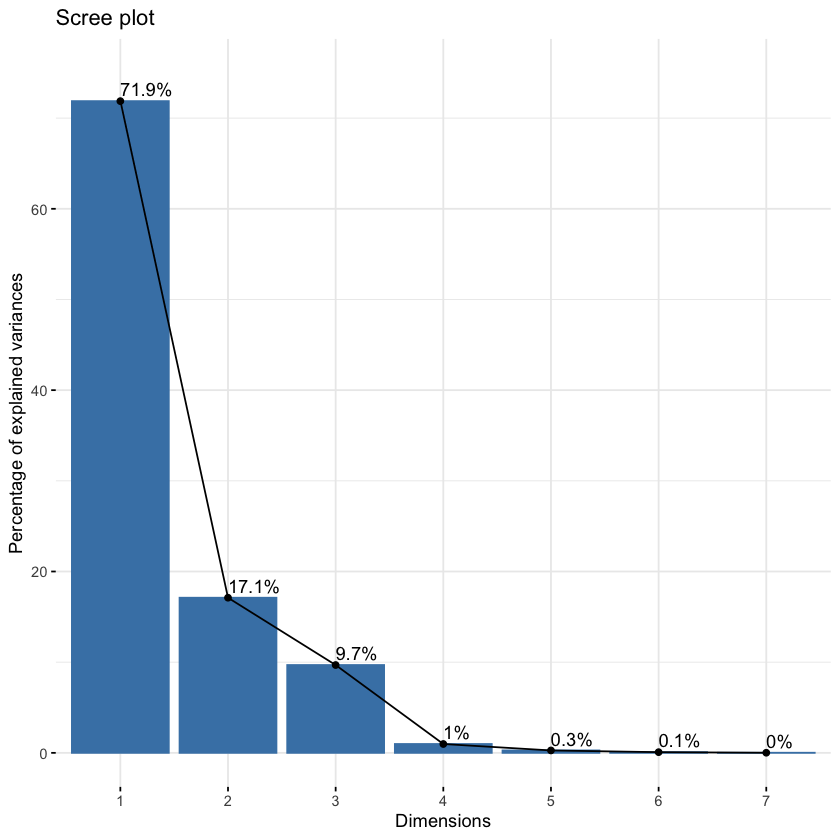

In [7]:
mypr <- prcomp(seeds[,1:7], center = T, scale = T)
summary(mypr)
fviz_eig(mypr, addlabels = TRUE, ylim = c(0, 75))
var <- get_pca_var(mypr)


,Dim.1,Dim.2,Dim.3,Dim.4,Dim.5,Dim.6,Dim.7
Area,0.99394755,0.0008450341,0.0004537914,0.0025634244,0.0007819319,9.696239e-04,4.386450e-04
Perimeter,0.98101057,0.0084506414,0.0024277403,0.0059678495,0.0005683714,1.209325e-03,3.655035e-04
Compactness,0.38608745,0.3353216539,0.2688363174,0.0075725112,0.0020708334,1.069541e-04,4.276371e-06
Length_of_Kernel,0.90262715,0.0508079572,0.0304376025,0.0047433348,0.0109831433,3.990721e-04,1.739726e-06
Width_of_Kernel,0.94250493,0.0163067144,0.0317746687,0.0027244812,0.0040527146,2.635233e-03,1.254041e-06
Asymmetry_Coefficient,0.07087908,0.6154564499,0.3130532976,0.0005844986,0.0000246020,2.057118e-06,1.126317e-08
Length_of_Kernel_Groove,0.75414445,0.1703843961,0.0310200207,0.0442083772,0.0002320124,9.781033e-06,9.668487e-07


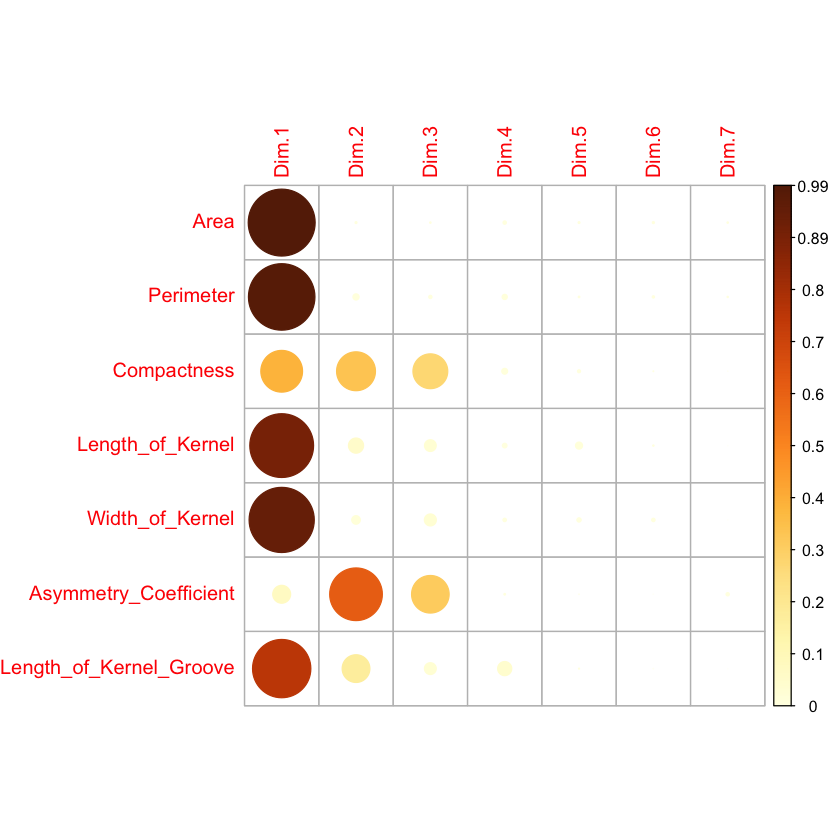

In [8]:

var$cos2
corrplot(var$cos2, is.corr=FALSE)


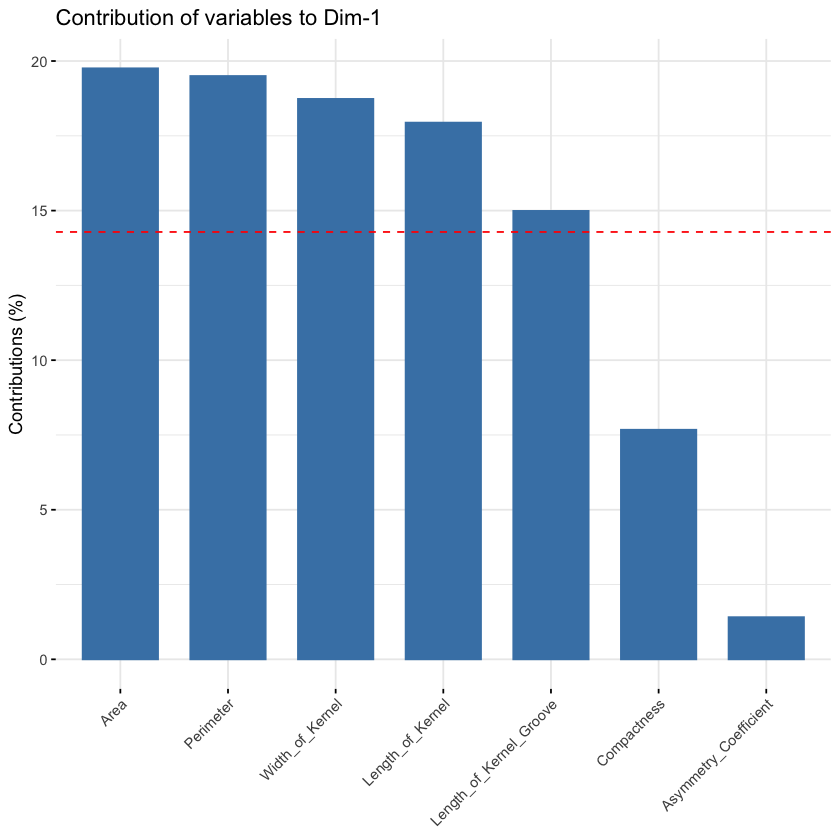

In [9]:

    fviz_contrib(mypr, choice = "var", axes = 1, top = 7)


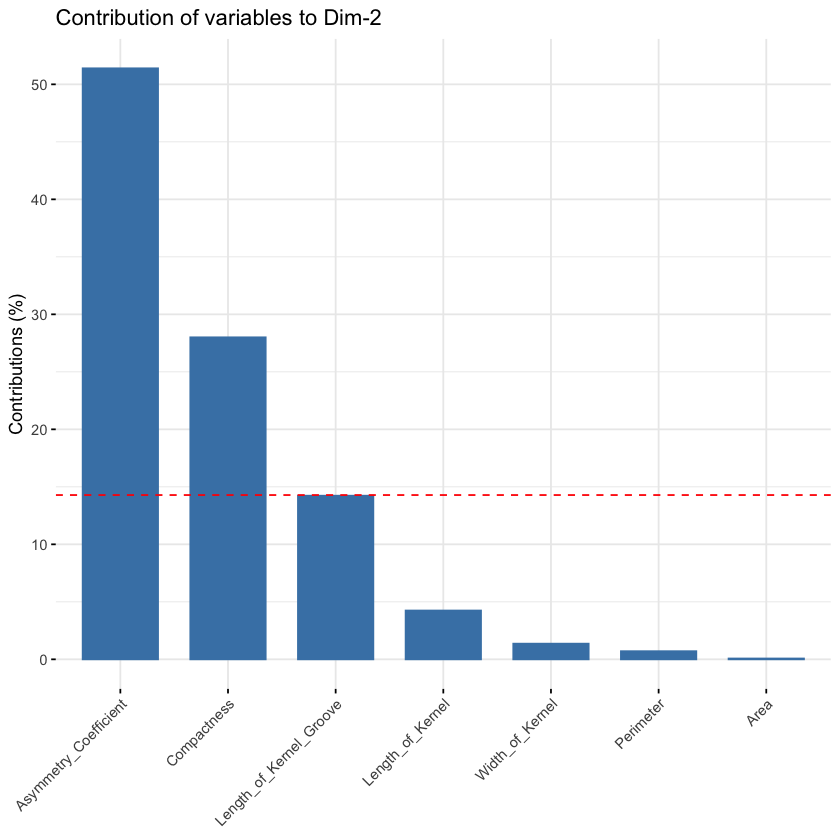

In [10]:
fviz_contrib(mypr, choice = "var", axes = 2, top = 7)


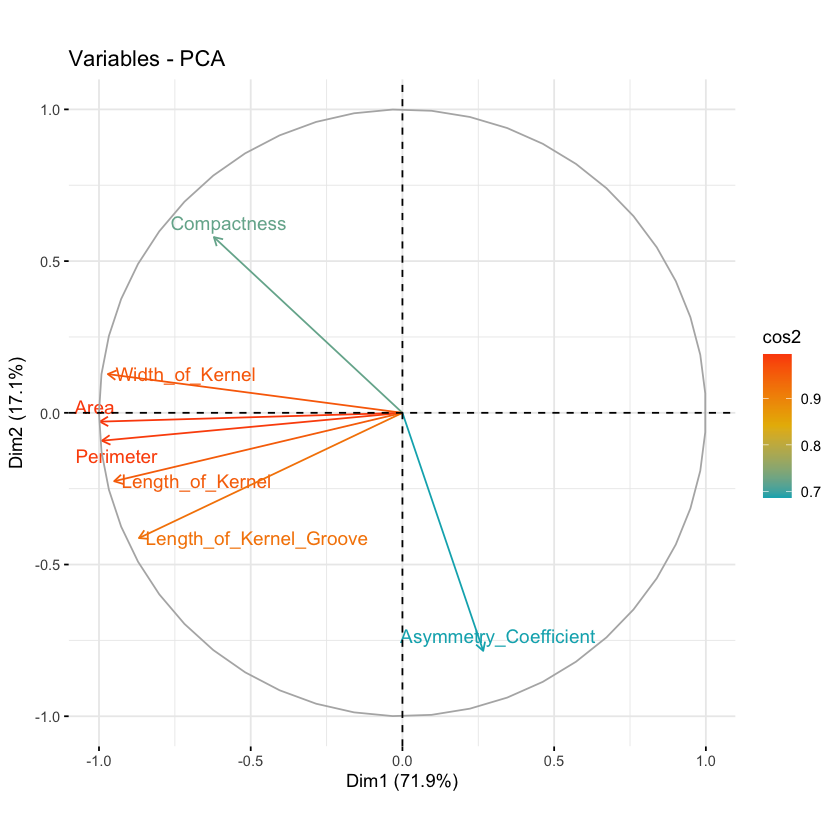

In [11]:

fviz_pca_var(mypr, col.var = "cos2",
             gradient.cols = c("#00AFBB", "#E7B800", "#FC4E07"),
             repel = TRUE # Avoid text overlapping
)


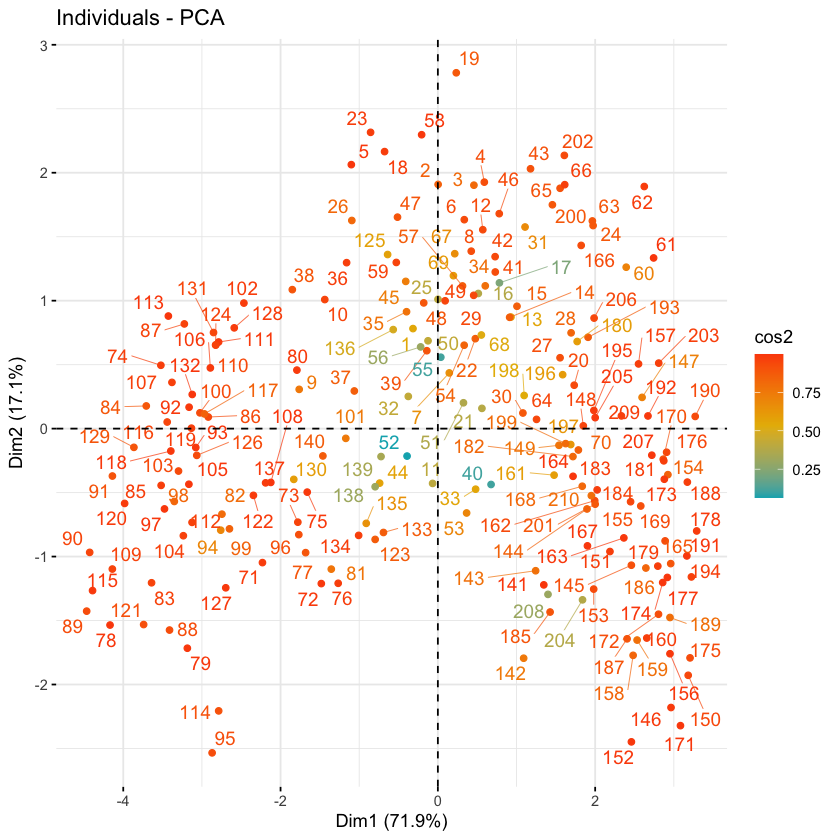

In [12]:
fviz_pca_ind(mypr,
             col.ind = "cos2", # Color by the quality of representation
             gradient.cols = c("#00AFBB", "#E7B800", "#FC4E07"),
             repel = TRUE # Avoid text overlapping
)


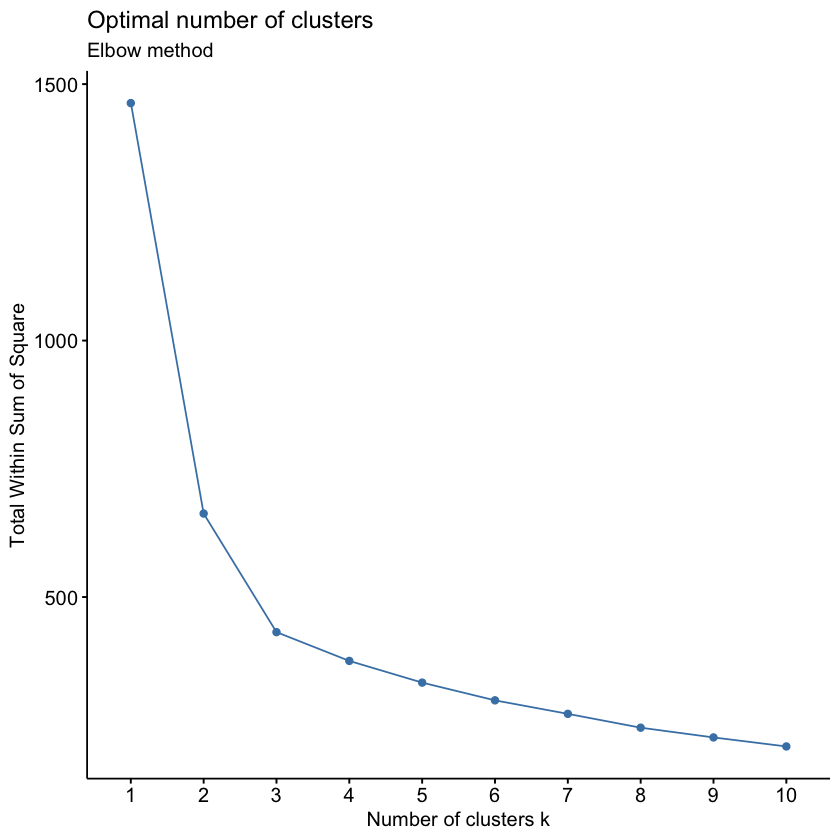

In [13]:
set.seed(123)
fviz_nbclust(scale_data,pam,method = "wss",nstart = 25)+
  labs(subtitle = "Elbow method")


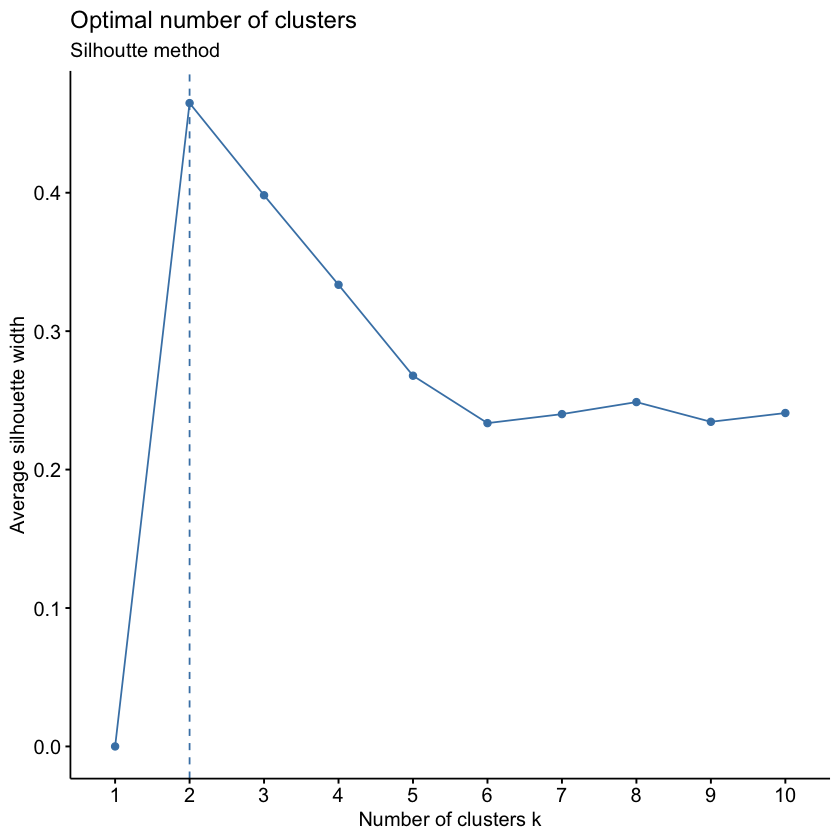

In [14]:
fviz_nbclust(scale_data,pam,method = "silhouette")+ #for average silhouette width
  labs(subtitle = "Silhoutte method")


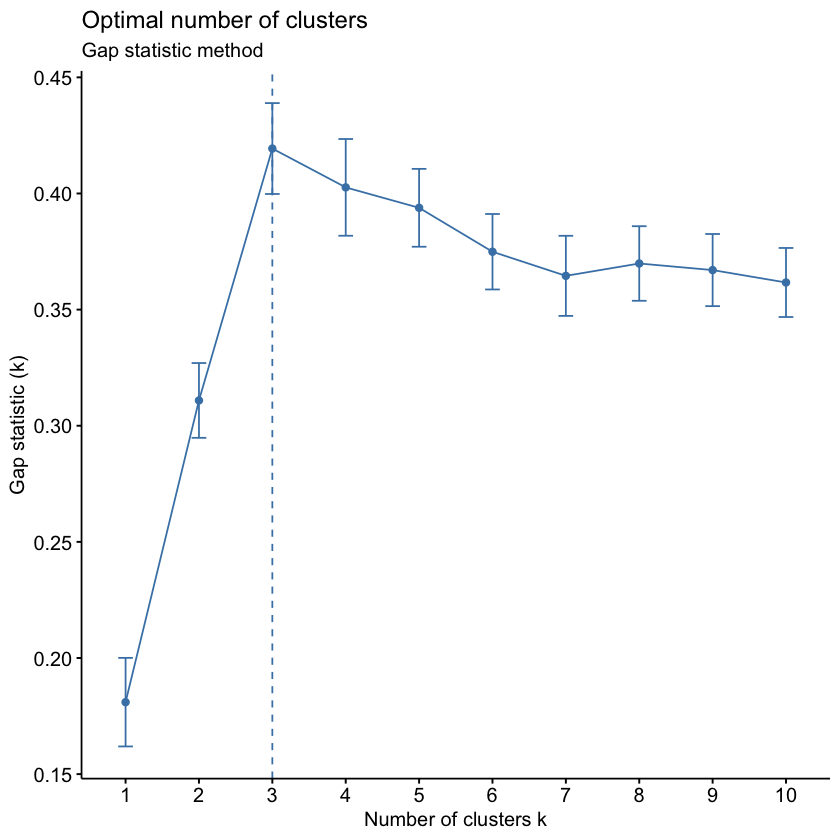

In [15]:
fviz_nbclust(scale_data, pam, method= "gap")+
  labs(subtitle = "Gap statistic method") #or gap statistics


In [16]:
set.seed(123)
pam_data_scaled <- pam(scale_data,3)
print(pam_data_scaled)
pam_data_scaled$medoids
pam_data_scaled$clustering
pam_data_scaled$clusinfo


Medoids:
      ID        Area  Perimeter Compactness Length_of_Kernel Width_of_Kernel
[1,]  49 -0.01976967 -0.0300819   0.4613499       -0.1885358      0.08576648
[2,] 105  1.40993126  1.4247880   0.5036700        1.3981443      1.31420772
[3,] 163 -0.96144769 -0.8800322  -1.2441514       -0.8159854     -1.08972470
     Asymmetry_Coefficient Length_of_Kernel_Groove
[1,]            -0.6625628              -0.6044419
[2,]            -0.2209434               1.5055095
[3,]             0.8565016              -0.7366954
Clustering vector:
  [1] 1 1 1 1 1 1 1 1 2 1 1 1 1 1 1 1 1 1 1 3 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1
 [38] 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 3 3 1 1 3 1 1 1 1 1 3 2 2 2 2
 [75] 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 1 2 2 2 2 2 2 2 2 2 2
[112] 2 2 2 2 2 2 2 2 2 2 2 1 2 1 2 2 2 2 2 2 2 1 1 1 1 2 1 1 2 3 3 3 3 3 3 3 3
[149] 3 3 3 3 3 3 3 3 3 3 3 3 3 3 3 3 3 1 3 3 3 3 3 3 3 3 3 3 3 3 3 3 3 3 3 3 3
[186] 3 3 3 3 3 3 3 3 3 3 3 3 1 3 1 3 1 3 3 3 3 3 3 3 3
Obje

Area,Perimeter,Compactness,Length_of_Kernel,Width_of_Kernel,Asymmetry_Coefficient,Length_of_Kernel_Groove
-0.01976967,-0.0300819,0.4613499,-0.1885358,0.08576648,-0.6625628,-0.6044419
1.40993126,1.4247880,0.5036700,1.3981443,1.31420772,-0.2209434,1.5055095
-0.96144769,-0.8800322,-1.2441514,-0.8159854,-1.08972470,0.8565016,-0.7366954


[1] 1 1 1 1 1 1 1 1 2 1 1 1 1 1 1 1 1 1 1 3 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1
 [38] 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 3 3 1 1 3 1 1 1 1 1 3 2 2 2 2
 [75] 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 1 2 2 2 2 2 2 2 2 2 2
[112] 2 2 2 2 2 2 2 2 2 2 2 1 2 1 2 2 2 2 2 2 2 1 1 1 1 2 1 1 2 3 3 3 3 3 3 3 3
[149] 3 3 3 3 3 3 3 3 3 3 3 3 3 3 3 3 3 1 3 3 3 3 3 3 3 3 3 3 3 3 3 3 3 3 3 3 3
[186] 3 3 3 3 3 3 3 3 3 3 3 3 1 3 1 3 1 3 3 3 3 3 3 3 3

size,max_diss,av_diss,diameter,separation
77,2.769122,1.400510,4.601093,0.5747312
62,2.334422,1.322603,3.954075,0.5747312
71,3.168492,1.331149,5.155598,0.6125787


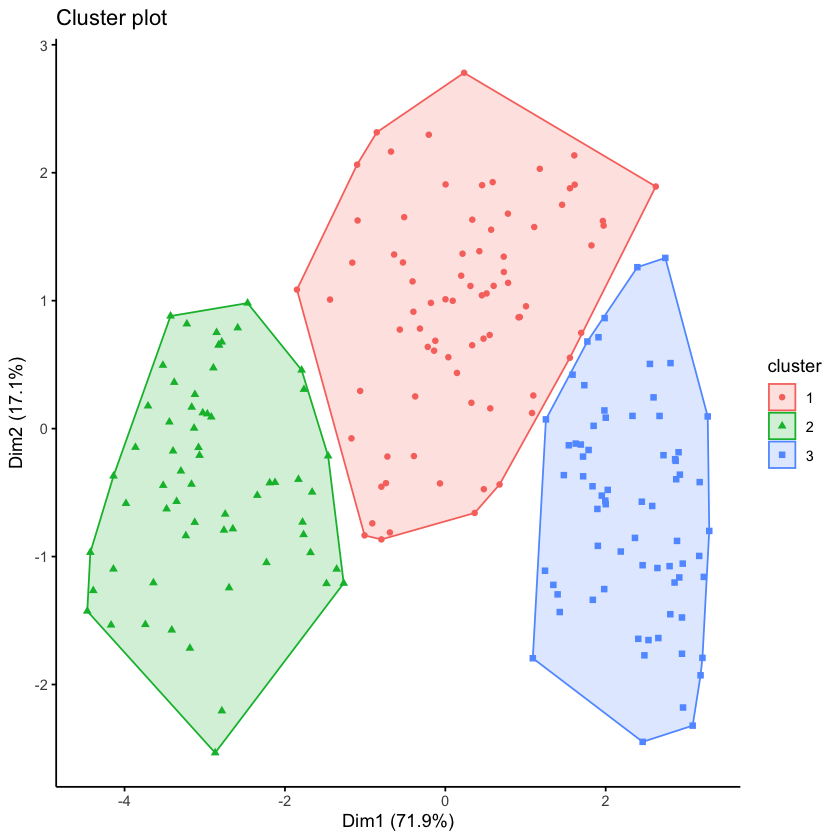

In [17]:

fviz_cluster(pam_data_scaled,
             ellipse.type = "convex",
             repel = TRUE, 
             geom = "point",
             ggtheme = theme_classic()
)


In [18]:

summary(seeds[1:7])
aggregate(seeds[1:7], by=list(pam_data_scaled$clustering), mean)  
aggregate(seeds[1:7], by=list(pam_data_scaled$clustering), sd)


      Area         Perimeter      Compactness     Length_of_Kernel
 Min.   :10.59   Min.   :12.41   Min.   :0.8081   Min.   :4.899   
 1st Qu.:12.27   1st Qu.:13.45   1st Qu.:0.8569   1st Qu.:5.262   
 Median :14.36   Median :14.32   Median :0.8734   Median :5.524   
 Mean   :14.85   Mean   :14.56   Mean   :0.8710   Mean   :5.629   
 3rd Qu.:17.30   3rd Qu.:15.71   3rd Qu.:0.8878   3rd Qu.:5.980   
 Max.   :21.18   Max.   :17.25   Max.   :0.9183   Max.   :6.675   
 Width_of_Kernel Asymmetry_Coefficient Length_of_Kernel_Groove
 Min.   :2.630   Min.   :0.7651        Min.   :4.519          
 1st Qu.:2.944   1st Qu.:2.5615        1st Qu.:5.045          
 Median :3.237   Median :3.5990        Median :5.223          
 Mean   :3.259   Mean   :3.7002        Mean   :5.408          
 3rd Qu.:3.562   3rd Qu.:4.7687        3rd Qu.:5.877          
 Max.   :4.033   Max.   :8.4560        Max.   :6.550          

Group.1,Area,Perimeter,Compactness,Length_of_Kernel,Width_of_Kernel,Asymmetry_Coefficient,Length_of_Kernel_Groove
<int>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>
1,14.51558,14.37455,0.8815247,5.524286,3.268597,2.794639,5.152299
2,18.67435,16.28065,0.8845500,6.207065,3.715113,3.591484,6.070113
3,11.86577,13.25648,0.8477493,5.236394,2.849127,4.777225,5.107338


Group.1,Area,Perimeter,Compactness,Length_of_Kernel,Width_of_Kernel,Asymmetry_Coefficient,Length_of_Kernel_Groove
<int>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>
1,1.1813022,0.5899611,0.01554290,0.2378912,0.1670804,1.196911,0.3009734
2,1.1439988,0.4889697,0.01463800,0.2181730,0.1567115,1.236550,0.2113246
3,0.7159223,0.3499228,0.01962849,0.1371776,0.1396313,1.331478,0.1789998


In [19]:

### Kmedoids with pca


summary(mypr)
set.seed(123)


Importance of components:
                          PC1    PC2     PC3     PC4     PC5     PC6     PC7
Standard deviation     2.2430 1.0943 0.82341 0.26147 0.13680 0.07302 0.02850
Proportion of Variance 0.7187 0.1711 0.09686 0.00977 0.00267 0.00076 0.00012
Cumulative Proportion  0.7187 0.8898 0.98668 0.99645 0.99912 0.99988 1.00000

In [20]:

data <- as.data.frame(mypr$x[, 1:2])
summary(data)


      PC1               PC2         
 Min.   :-4.4650   Min.   :-2.5342  
 1st Qu.:-1.8219   1st Qu.:-0.8087  
 Median : 0.3508   Median :-0.1274  
 Mean   : 0.0000   Mean   : 0.0000  
 3rd Qu.: 1.9078   3rd Qu.: 0.7861  
 Max.   : 3.2911   Max.   : 2.7811  

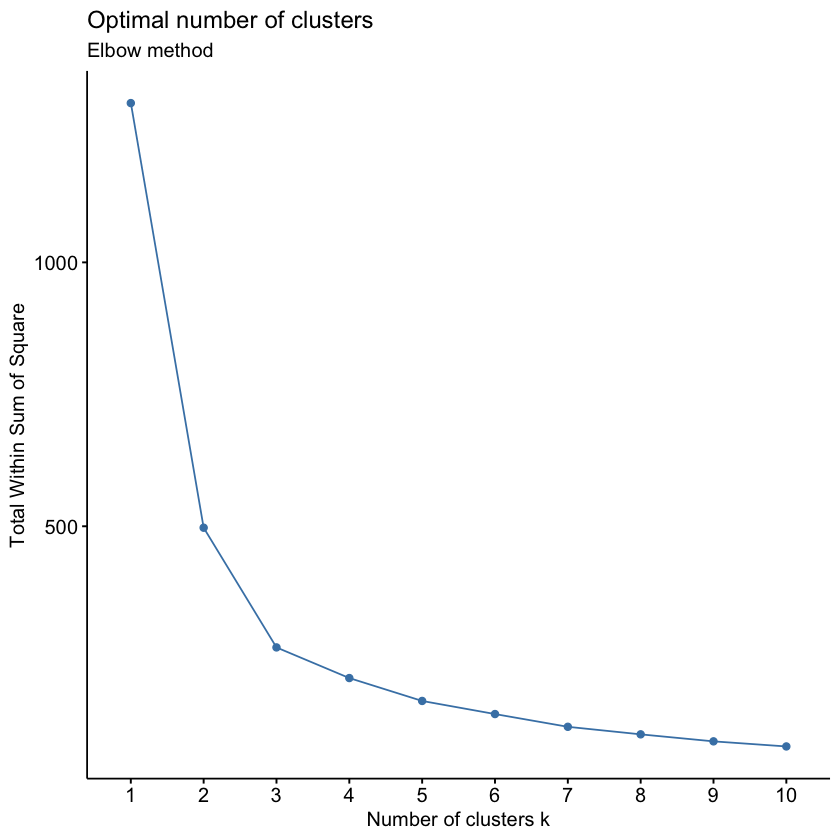

In [21]:

fviz_nbclust(data,pam,method = "wss",nstart = 25)+
  labs(subtitle = "Elbow method")


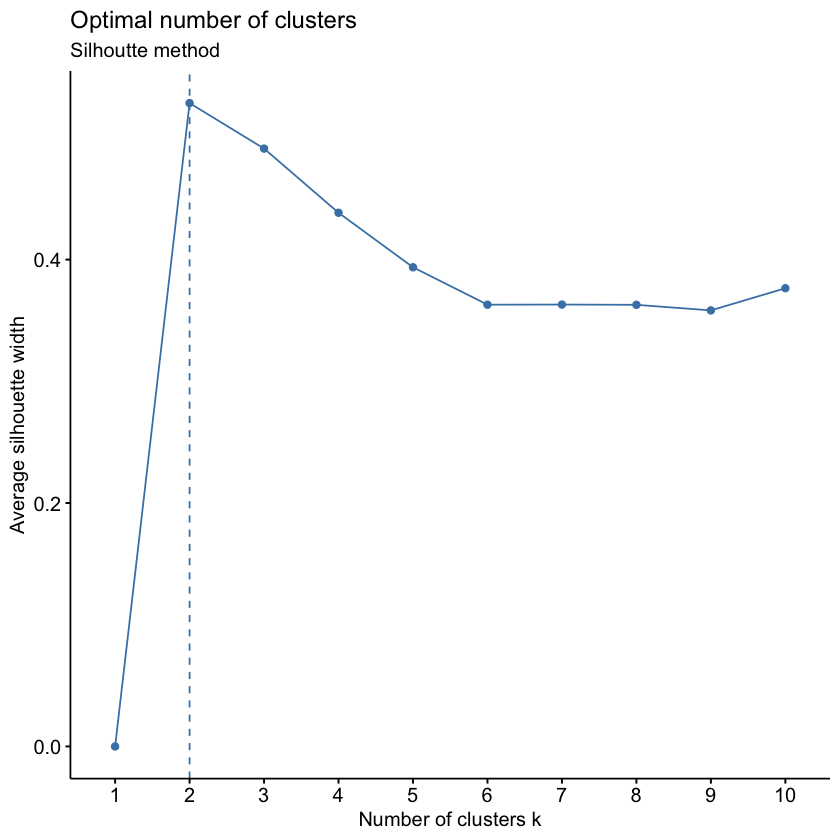

In [22]:
fviz_nbclust(data,pam,method = "silhouette")+ #for average silhouette width
  labs(subtitle = "Silhoutte method")


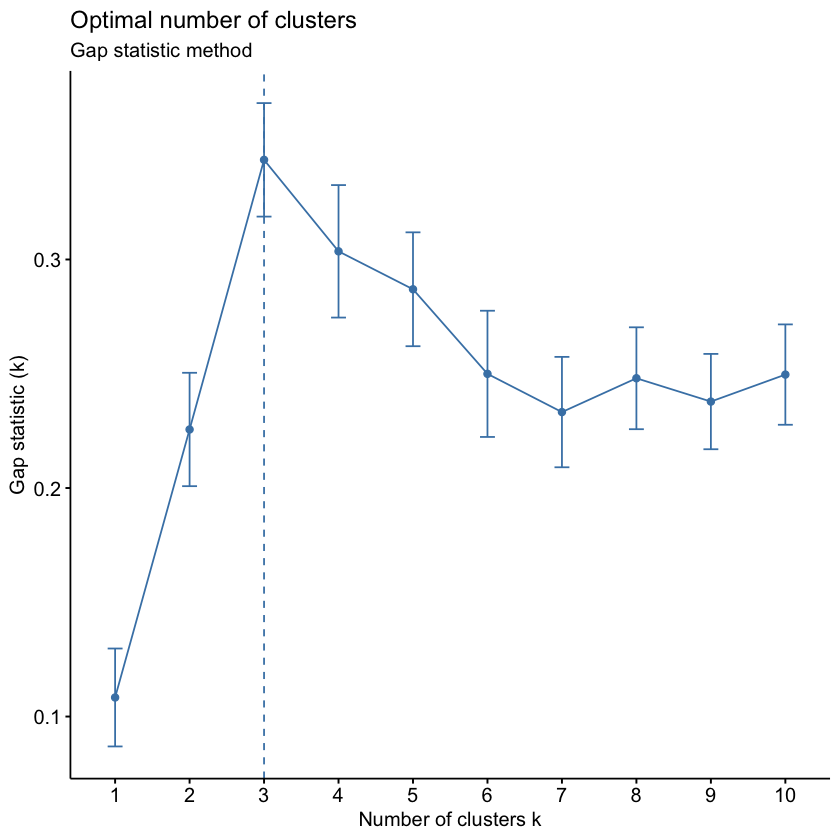

In [23]:
fviz_nbclust(data, pam, method= "gap")+
  labs(subtitle = "Gap statistic method") #or gap statistics


In [24]:
pam_data_pca <- pam(data,3)
print(pam_data_pca)
pam_data_pca$medoids
pam_data_pca$clustering
pam_data_pca$clusinfo



Medoids:
      ID         PC1        PC2
[1,]  49  0.09237903  0.9989885
[2,] 126 -3.06510214 -0.2091063
[3,] 184  2.45030353 -0.5713493
Clustering vector:
  [1] 1 1 1 1 1 1 1 1 2 1 1 1 1 1 1 1 1 1 1 3 1 1 1 1 1 1 3 3 1 1 1 1 1 1 1 1 1
 [38] 2 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 3 3 3 1 3 1 1 1 1 1 3 2 2 2 2
 [75] 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 1 2 2 2 2 2 2 2 2 2 2
[112] 2 2 2 2 2 2 2 2 2 2 2 1 2 1 2 2 2 2 2 2 2 1 1 1 1 2 1 1 2 3 3 3 3 3 3 3 3
[149] 3 3 3 3 3 3 3 3 3 3 3 3 3 3 3 3 3 1 3 3 3 3 3 3 3 3 3 3 3 3 3 3 3 3 3 3 3
[186] 3 3 3 3 3 3 3 3 3 3 3 3 1 3 1 3 1 3 3 3 3 3 3 3 3
Objective function:
   build     swap 
1.090709 1.018377 

Available components:
 [1] "medoids"    "id.med"     "clustering" "objective"  "isolation" 
 [6] "clusinfo"   "silinfo"    "diss"       "call"       "data"      


PC1,PC2
0.09237903,0.9989885
-3.06510214,-0.2091063
2.45030353,-0.5713493


[1] 1 1 1 1 1 1 1 1 2 1 1 1 1 1 1 1 1 1 1 3 1 1 1 1 1 1 3 3 1 1 1 1 1 1 1 1 1
 [38] 2 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 3 3 3 1 3 1 1 1 1 1 3 2 2 2 2
 [75] 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 1 2 2 2 2 2 2 2 2 2 2
[112] 2 2 2 2 2 2 2 2 2 2 2 1 2 1 2 2 2 2 2 2 2 1 1 1 1 2 1 1 2 3 3 3 3 3 3 3 3
[149] 3 3 3 3 3 3 3 3 3 3 3 3 3 3 3 3 3 1 3 3 3 3 3 3 3 3 3 3 3 3 3 3 3 3 3 3 3
[186] 3 3 3 3 3 3 3 3 3 3 3 3 1 3 1 3 1 3 3 3 3 3 3 3 3

size,max_diss,av_diss,diameter,separation
73,2.137912,1.0600373,3.957384,0.1803879
63,2.333222,1.0237521,3.761285,0.3221577
74,2.469755,0.9727041,4.343624,0.1803879


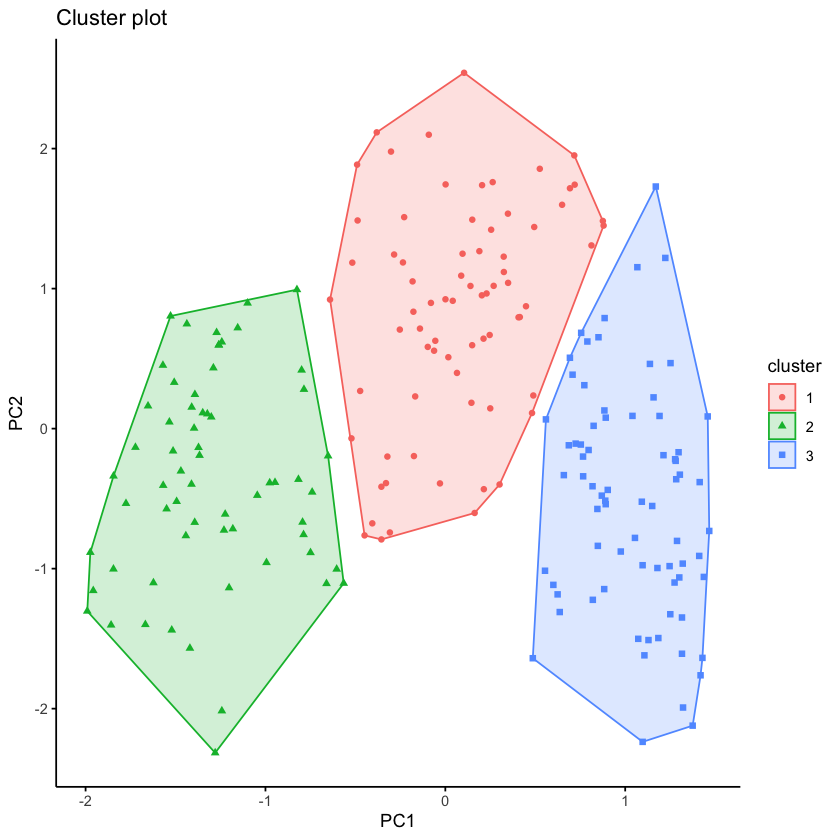

In [25]:
fviz_cluster(pam_data_pca,
             ellipse.type = "convex", 
             repel = TRUE, 
             geom = "point",
             ggtheme = theme_classic()
)


In [26]:
summary(seeds)


      Area         Perimeter      Compactness     Length_of_Kernel
 Min.   :10.59   Min.   :12.41   Min.   :0.8081   Min.   :4.899   
 1st Qu.:12.27   1st Qu.:13.45   1st Qu.:0.8569   1st Qu.:5.262   
 Median :14.36   Median :14.32   Median :0.8734   Median :5.524   
 Mean   :14.85   Mean   :14.56   Mean   :0.8710   Mean   :5.629   
 3rd Qu.:17.30   3rd Qu.:15.71   3rd Qu.:0.8878   3rd Qu.:5.980   
 Max.   :21.18   Max.   :17.25   Max.   :0.9183   Max.   :6.675   
 Width_of_Kernel Asymmetry_Coefficient Length_of_Kernel_Groove
 Min.   :2.630   Min.   :0.7651        Min.   :4.519          
 1st Qu.:2.944   1st Qu.:2.5615        1st Qu.:5.045          
 Median :3.237   Median :3.5990        Median :5.223          
 Mean   :3.259   Mean   :3.7002        Mean   :5.408          
 3rd Qu.:3.562   3rd Qu.:4.7687        3rd Qu.:5.877          
 Max.   :4.033   Max.   :8.4560        Max.   :6.550          

[1] "Accuracy Score for PAM on Scaled Data: 0.90952380952381"


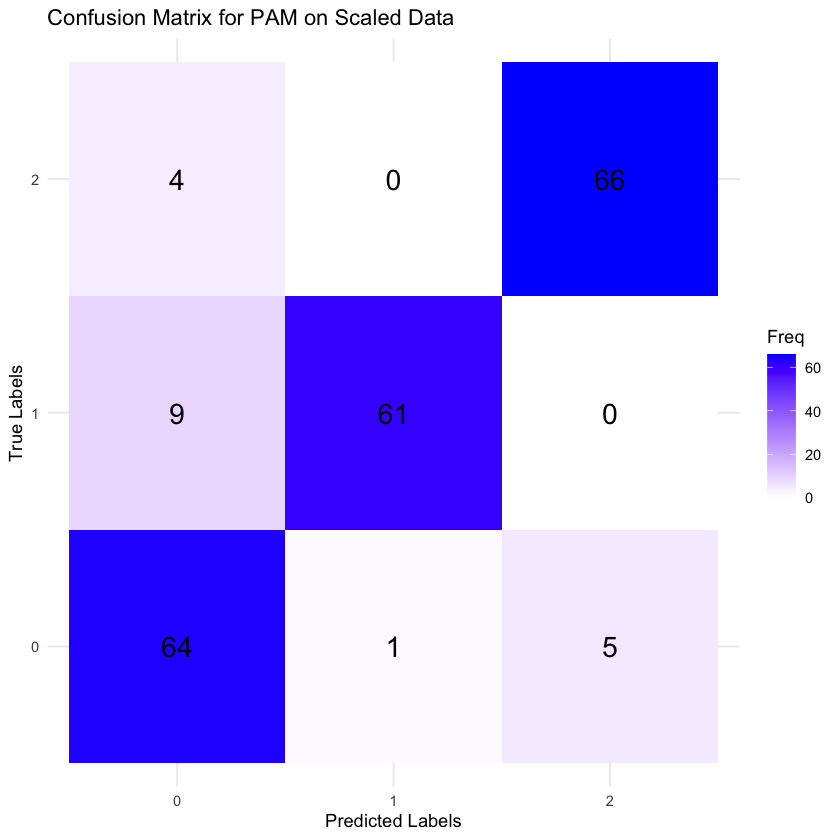

[1] "Accuracy Score for PAM on PCA Data: 0.89047619047619"


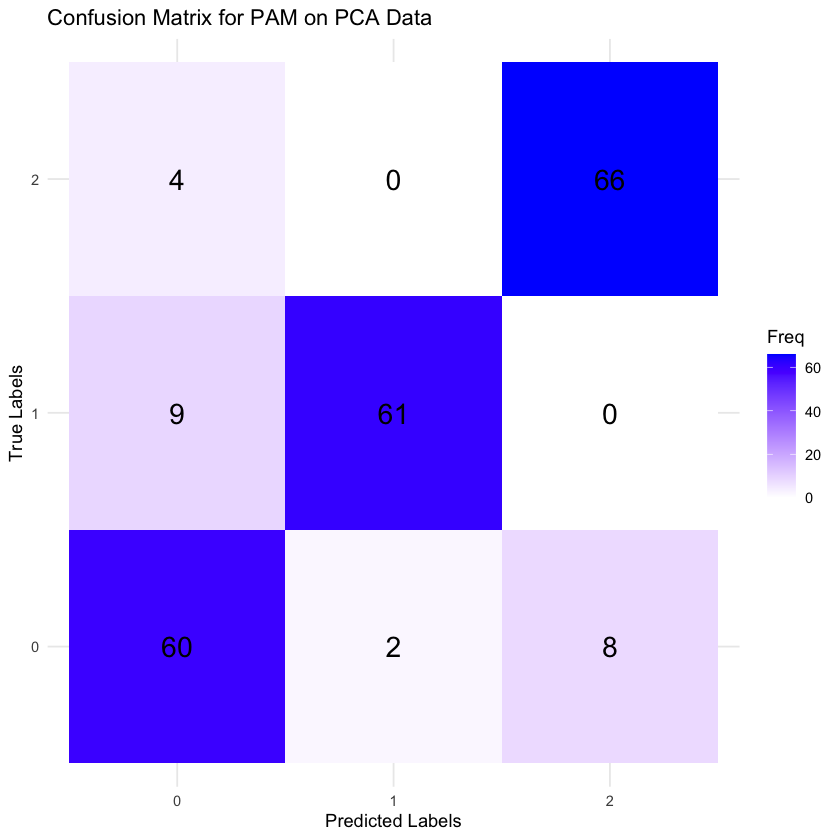

In [27]:
# Gerekli paketleri yükleyin
libraries <- c("plotly", "corrplot", "pastecs", "dplyr", "factoextra", "tidyverse", "ggplot2", "reshape2", "caret", "cluster", "ggpubr")

load_libraries <- function(libraries) {
  for (lib in libraries) {
    if (!require(lib, character.only = TRUE)) {
      install.packages(lib, dependencies = TRUE)
      suppressPackageStartupMessages(library(lib, character.only = TRUE))
    } else {
      suppressPackageStartupMessages(library(lib, character.only = TRUE))
    }
  }
}

# Paketleri yükleyin ve yüklemeyi kontrol edin
load_libraries(libraries)

# Veri setini yükleyin ve sütun isimlerini ayarlayın
seeds <- read.csv("Seed_Data.csv", header = FALSE)
seeds <- seeds[-1, ]
col_names <- c("Area", "Perimeter", "Compactness", "Length_of_Kernel", "Width_of_Kernel", "Asymmetry_Coefficient", "Length_of_Kernel_Groove", "Varieties_of_Wheat")
colnames(seeds) <- col_names
seeds <- data.frame(lapply(seeds, as.numeric))
seeds$Varieties_of_Wheat <- factor(seeds$Varieties_of_Wheat)

# PCA uygulanmış veri seti
pca_result <- prcomp(seeds[, 1:7], center = TRUE, scale = TRUE)
pca_data <- as.data.frame(pca_result$x[, 1:2])

# PAM clustering on scaled data
set.seed(123)
pam_data_scaled <- pam(scale(seeds[, 1:7]), 3)

# PAM clustering on PCA data
pam_data_pca <- pam(pca_data, 3)

# Function to align predicted labels with true labels
align_labels <- function(predicted_labels, true_labels) {
  aligned_labels <- rep(NA, length(predicted_labels))
  unique_clusters <- unique(predicted_labels)
  for (cluster in unique_clusters) {
    class_counts <- table(true_labels[predicted_labels == cluster])
    if (length(class_counts) > 0) {
      true_class <- names(sort(class_counts, decreasing = TRUE))[1]
      aligned_labels[predicted_labels == cluster] <- true_class
    }
  }
  return(aligned_labels)
}

# True labels
true_labels <- seeds$Varieties_of_Wheat

# Align predicted labels for scaled data
pam_labels_scaled <- pam_data_scaled$clustering
aligned_labels_scaled <- align_labels(pam_labels_scaled, true_labels)

# Confusion matrix and accuracy for scaled data
conf_matrix_scaled <- table(aligned_labels_scaled, true_labels)
accuracy_scaled <- sum(diag(conf_matrix_scaled)) / sum(conf_matrix_scaled)

# Plot confusion matrix for scaled data
conf_matrix_scaled_long <- as.data.frame(as.table(conf_matrix_scaled))
colnames(conf_matrix_scaled_long) <- c("Predicted", "True", "Freq")
ggplot(data = conf_matrix_scaled_long, aes(x = Predicted, y = True, fill = Freq)) +
  geom_tile() +
  scale_fill_gradient(low = "white", high = "blue") +
  geom_text(aes(label = Freq), size = 6) +
  labs(title = "Confusion Matrix for PAM on Scaled Data",
       x = "Predicted Labels", y = "True Labels", fill = "Freq") +
  theme_minimal()

# Print accuracy
print(paste("Accuracy Score for PAM on Scaled Data:", accuracy_scaled))

# Align predicted labels for PCA data
pam_labels_pca <- pam_data_pca$clustering
aligned_labels_pca <- align_labels(pam_labels_pca, true_labels)

# Confusion matrix and accuracy for PCA data
conf_matrix_pca <- table(aligned_labels_pca, true_labels)
accuracy_pca <- sum(diag(conf_matrix_pca)) / sum(conf_matrix_pca)

# Plot confusion matrix for PCA data
conf_matrix_pca_long <- as.data.frame(as.table(conf_matrix_pca))
colnames(conf_matrix_pca_long) <- c("Predicted", "True", "Freq")
ggplot(data = conf_matrix_pca_long, aes(x = Predicted, y = True, fill = Freq)) +
  geom_tile() +
  scale_fill_gradient(low = "white", high = "blue") +
  geom_text(aes(label = Freq), size = 6) +
  labs(title = "Confusion Matrix for PAM on PCA Data",
       x = "Predicted Labels", y = "True Labels", fill = "Freq") +
  theme_minimal()

# Print accuracy
print(paste("Accuracy Score for PAM on PCA Data:", accuracy_pca))
